In [1]:
import numpy as np
import pandas as pd
import rasterio as rio
from pathlib import Path
from tqdm import tqdm
from scipy.ndimage import distance_transform_edt   # for reachable-surplus distance-to-demand
import matplotlib.pyplot as plt

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
(RESULTS / 'extraction-rasters').mkdir(parents=True, exist_ok=True)

# Map extraction — allocation (unified BAU↔CON, all CE scenarios)

Merges the former `5-2` (BAU) and `5-3` (CON): they shared identical trade/allocation code and differed only in the conservation knob β, so they are a single parametrized routine here (one source of truth).

## Sort key
score = (1−β)·d̃ + β·R̃W̃R̃  (min-max normalized per window; lowest first)
- β = 0.0 → **BAU** (transport-work only)
- β = 1.0 → **CON** (biodiversity / RWR only)
- 0 < β < 1 → blended (higher β = more conservation)

## Two crossed axes (trade-off surface)
- **Demand axis** — CE scenario: `BAU → HIC → HIC+UMIC → HIC+UMIC+LMIC → CE` (MFA, downscaled in `1-downscale-extraction-demand`).
- **Allocation axis** — β ∈ {0, 0.2, 0.4, 0.6, 0.8, 1.0}.

5 × 6 = 30 allocations at the central demand/reserve case (M/M).

## Output (per scenario × β)
`allocated-extraction-2023-2050-{scenario}-B{β}-{res}-D{Ld}-R{Lr}.tif` (+ trade-summary, trade-matrix, domestic-flows CSVs).

In [3]:
cpv     = pd.read_csv(DATA / 'country-pseudo-values.csv')
T_hist  = pd.read_csv(RESULTS / 'historical-trade-matrix.csv', index_col=0)
dist_df = pd.read_csv(RESULTS / 'bilateral-distance-matrix.csv', index_col=0)

iso2code = dict(zip(cpv['country'], cpv['value']))
iso2name = dict(zip(cpv['country'], cpv['full name']))

trade_iso   = sorted(set(dist_df.index) & set(cpv['country']))
trade_codes = np.array([iso2code[iso] for iso in trade_iso])
n_trade     = len(trade_iso)

D_MATRIX = dist_df.reindex(index=trade_iso, columns=trade_iso).values.astype(np.float64)
np.fill_diagonal(D_MATRIX, np.nan)

T_SEED = np.zeros((n_trade, n_trade), dtype=np.float64)
common_iso = sorted(set(T_hist.index) & set(trade_iso))
if common_iso:
    idx_in_trade   = [trade_iso.index(iso) for iso in common_iso]
    T_seed_common  = T_hist.loc[common_iso, common_iso].values
    for ii, i in enumerate(idx_in_trade):
        T_SEED[i, idx_in_trade] = T_seed_common[ii]
np.fill_diagonal(T_SEED, 0.0)

print(f'Trade countries: {n_trade}  | T_SEED nonzero pairs: {(T_SEED > 0).sum()}')

Trade countries: 235  | T_SEED nonzero pairs: 18632


In [5]:
def _ipf(deficit, surplus, seed, n_iter=50, eps=1e-12):
    T = seed.astype(np.float64).copy()
    cs = T.sum(0)
    T *= np.where(cs > eps, deficit / np.maximum(cs, eps), 0.0)[None, :]
    for _ in range(n_iter):
        rs = T.sum(1)
        over = rs > surplus + 1e-6
        if not over.any():
            break
        T *= np.where(over, surplus / np.maximum(rs, eps), 1.0)[:, None]
        cs = T.sum(0)
        T *= np.where(cs > eps, deficit / np.maximum(cs, eps), 1.0)[None, :]
    return T

In [6]:
def gravity_trade(deficit, surplus, T_seed, dist_matrix, n_iter=50, eps=1e-12):
    """Two-stage trade: historical RAS + distance-gravity fallback (identical to 5-2)."""
    T1 = _ipf(deficit, surplus, T_seed, n_iter=n_iter, eps=eps)

    residual_deficit = np.maximum(deficit - T1.sum(axis=0), 0.0)
    residual_surplus = np.maximum(surplus - T1.sum(axis=1), 0.0)

    T2 = np.zeros_like(T1)
    if residual_deficit.sum() > eps and residual_surplus.sum() > eps:
        with np.errstate(divide='ignore', invalid='ignore'):
            inv_d = np.where(np.isnan(dist_matrix) | (dist_matrix <= 0), 0.0, 1.0 / dist_matrix)
        seed_gravity = residual_surplus[:, None] * residual_deficit[None, :] * inv_d
        T2 = _ipf(residual_deficit, residual_surplus, seed_gravity, n_iter=n_iter, eps=eps)

    return T1 + T2

In [7]:
def allocate_country(demand_raster, capacity_raster, rarity_raster, max_r,
                     beta=0.0, cell_size_km=50.0):
    """Same unified allocator as 5-2 (identical code).

    Score (min-max normalized within each candidate window), lowest-score cell first:
        score = (1 - beta) * d_norm  +  beta * RWR_norm

        beta = 0.0  -> BAU (minimize transport work)
        beta = 1.0  -> CON (minimize biodiversity impact only; lowest-RWR first)
        0 < beta < 1 -> blended; beta is the conservation-strength knob

    Returns: allocated (Mt), remained_demand (Mt), remained_capacity (Mt),
             transport_work (Mt*km), flows (list of point-to-point records).
    """
    H, W = demand_raster.shape
    allocated         = np.zeros_like(demand_raster, dtype=np.float64)
    remained_demand   = (demand_raster.astype(np.float64) / 1e6).copy()  # tonnes -> Mt
    remained_capacity = capacity_raster.astype(np.float64).copy()
    transport_work    = 0.0
    flows             = []

    i_set, j_set = np.where(remained_demand > 0)
    if len(i_set) == 0:
        return allocated, remained_demand, remained_capacity, transport_work, flows

    order = np.argsort(-remained_demand[i_set, j_set])

    for idx in order:
        i, j = int(i_set[idx]), int(j_set[idx])
        a_demand = remained_demand[i, j]
        if a_demand <= 0:
            continue

        i0, i1 = max(0, i - max_r), min(H, i + max_r + 1)
        j0, j1 = max(0, j - max_r), min(W, j + max_r + 1)
        cap_slice = remained_capacity[i0:i1, j0:j1]
        m = cap_slice > 0
        if not m.any():
            continue

        cand = np.argwhere(m)
        ei = i0 + cand[:, 0]; ej = j0 + cand[:, 1]
        dists = np.hypot(ei - i, ej - j) * cell_size_km

        if beta <= 0.0:
            score = dists                                            # pure distance (BAU)
        elif beta >= 1.0:
            score = rarity_raster[ei, ej].astype(np.float64)         # pure RWR (CON)
        else:
            d_range = dists.max() - dists.min()
            d_norm = (dists - dists.min()) / d_range if d_range > 0 else np.zeros_like(dists)
            rwr = rarity_raster[ei, ej].astype(np.float64)
            r_range = rwr.max() - rwr.min()
            r_norm = (rwr - rwr.min()) / r_range if r_range > 0 else np.zeros_like(rwr)
            score = (1.0 - beta) * d_norm + beta * r_norm

        for k in np.argsort(score):
            ek, fk = int(ei[k]), int(ej[k])
            cap_here = remained_capacity[ek, fk]
            if cap_here <= 0:
                continue
            alloc = min(a_demand, cap_here)
            d_km = float(dists[k])
            allocated[ek, fk]         += alloc
            remained_capacity[ek, fk] -= alloc
            transport_work            += alloc * d_km
            flows.append((i, j, ek, fk, float(alloc), d_km))
            a_demand -= alloc
            if a_demand <= 0:
                break

        remained_demand[i, j] = a_demand

    return allocated, remained_demand, remained_capacity, transport_work, flows

In [8]:
def allocate_demand_to_extraction(scenario, demand_level, reserve_level, beta, max_r=3,
                                       max_r_surplus=10, res='50km', cell_size_km=50.0,
                                       archipelago_max_r=None):
    """CON allocation: distance+RWR blended domestic sort + two-radius trade + export production.

    Identical structure to 5-2 BAU, with ONE difference: the within-country sort (domestic AND
    export production) uses the blended score  (1-beta)*d_norm + beta*RWR_norm.
        beta = 0.0 -> BAU (distance only)   ...   beta = 1.0 -> CON (RWR only).

      max_r          : domestic first-pass radius (3 = 150 km).
      max_r_surplus  : economic-accessibility radius (10 = 500 km); reserve farther than this from
                       domestic demand is stranded and is NOT exportable surplus.
      archipelago_max_r : {country_code: max_r} — island nations (Indonesia 124, Philippines 249)
                       get a larger domestic radius so intra-archipelago supply is not
                       misclassified as international import.
    """
    if archipelago_max_r is None:
        archipelago_max_r = {124: 10, 249: 10}   # Indonesia, Philippines -> 500 km domestic radius

    country_raster_ = rio.open(RESULTS / 'country-rasters' / f'country-raster-eck4-{res}.tif')
    economy_raster_ = rio.open(RESULTS / 'economy-rasters' / f'economy-raster-eck4-{res}.tif')
    country_raster  = country_raster_.read(1)
    economy_raster  = economy_raster_.read(1)

    # --- demand (tonnes) ---
    sand      = rio.open(RESULTS / 'extraction-rasters' / f'sand-extraction-demand-2023-2050-{scenario}-{res}-{demand_level}.tif').read(1)
    gravel    = rio.open(RESULTS / 'extraction-rasters' / f'gravel-extraction-demand-2023-2050-{scenario}-{res}-{demand_level}.tif').read(1)
    limestone = rio.open(RESULTS / 'extraction-rasters' / f'limestone-extraction-demand-2023-2050-{scenario}-{res}-{demand_level}.tif').read(1)
    total_demand = sand + gravel + limestone                                    # tonnes
    global_demand_Gt = total_demand.sum() / 1e9

    # --- reserve (Mt) + RWR (biodiversity) ---
    reserve = rio.open(RESULTS / 'mining-area' / f'aggregate-reserve-{res}-{reserve_level}.tif').read(1)
    RWR     = rio.open(RESULTS / f'area-of-habitat-{res}' / f'rarity-weighted-richness-vertebrates-{res}.tif').read(1)

    # ===================== LAYER 1: domestic allocation =====================
    domestic_extraction      = np.zeros(country_raster.shape, dtype=np.float64)
    remained_demand_global   = np.zeros(country_raster.shape, dtype=np.float64)
    remained_capacity_global = np.zeros(country_raster.shape, dtype=np.float64)
    domestic_transport_work  = 0.0
    all_flows                = []

    country_codes = np.unique(country_raster); country_codes = country_codes[country_codes > 0]

    for code in tqdm(country_codes, desc=f'Domestic allocation (beta={beta:.2f})'):
        mask  = (country_raster == code)
        r_dom = archipelago_max_r.get(int(code), max_r)                        # larger radius for island nations
        alloc, remain_dem, remain_cap, tw, flows = allocate_country(
            total_demand * mask, reserve * mask,
            rarity_raster=RWR, max_r=r_dom,
            beta=beta,                                                         # conservation knob
            cell_size_km=cell_size_km,
        )
        domestic_extraction      += alloc
        remained_demand_global   += remain_dem
        remained_capacity_global += remain_cap
        domestic_transport_work  += tw
        all_flows.extend(flows)

    # ===================== LAYER 2: reachable surplus =====================
    remained_capacity_global = np.where(economy_raster > 0, remained_capacity_global, 0)

    reachable_surplus = np.zeros(country_raster.shape, dtype=np.float64)
    dist_to_demand    = np.full(country_raster.shape, np.nan, dtype=np.float64)
    nn_i = np.full(country_raster.shape, -1, dtype=np.int32)
    nn_j = np.full(country_raster.shape, -1, dtype=np.int32)

    for code in country_codes:
        mask = (country_raster == code)
        demand_mask = mask & (total_demand > 0)
        if not demand_mask.any():
            continue                                                            # no domestic demand -> strand all reserve
        dcells, (ii, jj) = distance_transform_edt(~demand_mask, return_indices=True)
        within = mask & (dcells <= max_r_surplus)
        reachable_surplus[within] = remained_capacity_global[within]
        dist_to_demand[mask] = dcells[mask] * cell_size_km
        nn_i[mask] = ii[mask]
        nn_j[mask] = jj[mask]

    # ===================== LAYER 3: two-stage trade on reachable surplus =====================
    deficit_vec = np.array([remained_demand_global[country_raster == c].sum() for c in trade_codes])
    surplus_vec = np.array([reachable_surplus[country_raster == c].sum()      for c in trade_codes])

    T = gravity_trade(deficit_vec, surplus_vec, T_SEED, D_MATRIX)
    export_vec = T.sum(1)
    import_vec = T.sum(0)

    # ===================== LAYER 4: export production from reachable surplus =====================
    # Produce each exporter's traded volume from its own reachable cells, ranked by the SAME
    # conservation score: (1-beta)*dist_norm + beta*RWR_norm  (lowest first).
    # export_vec <= surplus_vec by construction => residual ~ 0.
    trade_extraction   = np.zeros(country_raster.shape, dtype=np.float64)
    export_residual_Mt = 0.0
    for k, code in enumerate(trade_codes):
        e = export_vec[k]
        if e <= 0:
            continue
        cmask = (country_raster == code) & (reachable_surplus > 0)
        if not cmask.any():
            export_residual_Mt += e
            continue
        cells = np.argwhere(cmask)
        cap   = remained_capacity_global[cmask].astype(np.float64)
        dist  = dist_to_demand[cmask]
        rwr   = RWR[cmask].astype(np.float64)

        if beta <= 0.0:
            score = dist                                                       # BAU: nearest-to-demand first
        elif beta >= 1.0:
            score = rwr                                                        # CON: lowest-RWR first
        else:
            d_rng = dist.max() - dist.min()
            d_norm = (dist - dist.min()) / d_rng if d_rng > 0 else np.zeros_like(dist)
            r_rng = rwr.max() - rwr.min()
            r_norm = (rwr - rwr.min()) / r_rng if r_rng > 0 else np.zeros_like(rwr)
            score = (1.0 - beta) * d_norm + beta * r_norm

        order = np.argsort(score)
        cap_s = cap[order]
        cumcap = np.cumsum(cap_s)
        cut = int(np.searchsorted(cumcap, e))
        alloc_s = np.zeros_like(cap_s)
        if cut > 0:
            alloc_s[:cut] = cap_s[:cut]
        if cut < len(cap_s):
            used = cumcap[cut - 1] if cut > 0 else 0.0
            alloc_s[cut] = e - used
        else:
            export_residual_Mt += e - cumcap[-1]
        alloc_cells = np.zeros_like(cap)
        alloc_cells[order] = alloc_s
        ci = cells[:, 0]; cj = cells[:, 1]
        trade_extraction[ci, cj]         += alloc_cells
        remained_capacity_global[ci, cj] -= alloc_cells
        nz = np.where(alloc_cells > 0)[0]
        domestic_transport_work += float((alloc_cells[nz] * dist[nz]).sum())
        for idx in nz:
            ei_, ej_ = int(cells[idx, 0]), int(cells[idx, 1])
            di_, dj_ = int(nn_i[ei_, ej_]), int(nn_j[ei_, ej_])
            all_flows.append((di_, dj_, ei_, ej_, float(alloc_cells[idx]), float(dist[idx])))

    trade_transport_work_diag = np.nansum(T * D_MATRIX)                         # diagnostic only

    # ===================== combine + report =====================
    final_extraction = domestic_extraction + trade_extraction
    unmet_Gt = (total_demand.sum() / 1e6 - final_extraction.sum()) / 1e3
    coverage = 100 * final_extraction.sum() / 1e3 / global_demand_Gt

    print(f'  ({scenario}-B{beta:.2f}-D{demand_level}-R{reserve_level}) coverage {coverage:.1f}% | '
          f'traded {export_vec.sum()/1e3:.2f} Gt | export-prod residual {export_residual_Mt/1e3:.3f} Gt | '
          f'UNMET {unmet_Gt:.3f} Gt')
    print(f'    reachable surplus pool: {surplus_vec.sum()/1e3:.1f} Gt '
          f'(rest stranded > {max_r_surplus*cell_size_km:.0f} km from demand)')
    print(f'    domestic transport work (incl. export production): {domestic_transport_work/1e3:.2f} Gt*km')
    print(f'    cross-border trade work (diagnostic only)        : {trade_transport_work_diag/1e3:.2f} Gt*km')
    print(f'    flow records: {len(all_flows):,}')

    trade_df = pd.DataFrame({
        'name'   : [iso2name.get(iso, iso) for iso in trade_iso],
        'deficit': deficit_vec,
        'surplus': surplus_vec,
        'import' : import_vec,
        'export' : export_vec,
    }, index=trade_iso)
    trade_df['net_import'] = trade_df['import'] - trade_df['export']
    T_df = pd.DataFrame(T, index=trade_iso, columns=trade_iso)

    # --- write outputs ---
    tag = f'{scenario}-B{beta:.2f}-{res}-D{demand_level}-R{reserve_level}'
    output_raster = RESULTS / 'extraction-rasters' / f'allocated-extraction-2023-2050-{tag}.tif'
    with rio.open(
        output_raster, 'w', driver='GTiff',
        height=country_raster.shape[0], width=country_raster.shape[1],
        count=1, dtype=final_extraction.dtype,
        crs=country_raster_.crs, transform=country_raster_.transform,
        compress='lzw',
    ) as dst:
        dst.write(final_extraction, 1)

    trade_df.to_csv(RESULTS / 'extraction-rasters' / f'trade-summary-{tag}.csv')
    T_df.to_csv(    RESULTS / 'extraction-rasters' / f'trade-matrix-{tag}.csv')

    flow_df = pd.DataFrame(
        all_flows,
        columns=['demand_i', 'demand_j', 'extract_i', 'extract_j', 'alloc_Mt', 'dist_km'],
    )
    flow_df.to_csv(
        RESULTS / 'extraction-rasters' / f'domestic-flows-{tag}.csv',
        index=False,
    )

    return final_extraction, trade_df, T_df, flow_df

## Run — scenario × β cross (30 allocations, M/M)

In [9]:
# SCENARIOS = ['BAU', 'HIC', 'HIC+UMIC', 'HIC+UMIC+LMIC', 'CE']
SCENARIOS = ['BAU', 'MIU', 'LE', 'RE', 'RC', 'SS', 'CCR', 'CE']

# --- single source of truth for the sweep grid ---
# Defined here in 5-2; written to sweep-config.json so the downstream notebooks
# (5-3-cost-analysis, 6-estimate-mining-area, 4/6-biodiversity-risk-assessment) READ these
# instead of re-defining them. Written before the (long) loop so it lands even if interrupted.

RWR_50km = rio.open(RESULTS / 'area-of-habitat-50km' / 'rarity-weighted-richness-vertebrates-50km.tif').read(1)

for scen in SCENARIOS:
    for D in ['L', 'M', 'H']:
        for R in ['L', 'M', 'H']:
            _, _, _, fdf = allocate_demand_to_extraction(scen, D, R, beta=0.0, max_r=3, max_r_surplus=10)
            rwr_at = RWR_50km[fdf['extract_i'].values, fdf['extract_j'].values]


Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:01<00:00, 115.65it/s]


  (BAU-B0.00-DL-RL) coverage 100.0% | traded 10.29 Gt | export-prod residual 0.000 Gt | UNMET 0.000 Gt
    reachable surplus pool: 91156.6 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 9851.09 Gt*km
    cross-border trade work (diagnostic only)        : 34523.17 Gt*km
    flow records: 41,123


Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:01<00:00, 153.22it/s]


  (BAU-B0.00-DL-RM) coverage 100.0% | traded 3.50 Gt | export-prod residual 0.000 Gt | UNMET 0.000 Gt
    reachable surplus pool: 211981.1 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 7772.24 Gt*km
    cross-border trade work (diagnostic only)        : 11640.86 Gt*km
    flow records: 40,926


Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:01<00:00, 122.09it/s]


...

  (CE-B0.00-DH-RL) coverage 100.0% | traded 12.13 Gt | export-prod residual 0.000 Gt | UNMET -0.000 Gt
    reachable surplus pool: 91138.2 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 10678.84 Gt*km
    cross-border trade work (diagnostic only)        : 40988.72 Gt*km
    flow records: 41,144


Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:01<00:00, 165.69it/s]


  (CE-B0.00-DH-RM) coverage 100.0% | traded 3.83 Gt | export-prod residual 0.000 Gt | UNMET -0.000 Gt
    reachable surplus pool: 211961.2 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 8490.43 Gt*km
    cross-border trade work (diagnostic only)        : 12825.29 Gt*km
    flow records: 40,933


Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:01<00:00, 156.09it/s]


  (CE-B0.00-DH-RH) coverage 100.0% | traded 2.19 Gt | export-prod residual 0.000 Gt | UNMET -0.000 Gt
    reachable surplus pool: 340117.3 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 7580.13 Gt*km
    cross-border trade work (diagnostic only)        : 7339.69 Gt*km
    flow records: 40,845


In [ ]:
# SCENARIOS = ['BAU', 'HIC', 'HIC+UMIC', 'HIC+UMIC+LMIC', 'CE']
SCENARIOS = ['BAU', 'CE10', 'CE20', 'CE30', 'CE40', 'CE50', 'CE60', 'CE70', 'CE80', 'CE90', 'CE']
BETAS     = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.90, 0.95, 1.0]

# --- single source of truth for the sweep grid ---
# Defined here in 5-2; written to sweep-config.json so the downstream notebooks
# (5-3-cost-analysis, 6-estimate-mining-area, 4/6-biodiversity-risk-assessment) READ these
# instead of re-defining them. Written before the (long) loop so it lands even if interrupted.
import json
json.dump({'SCENARIOS': SCENARIOS, 'BETAS': BETAS}, open(RESULTS / 'sweep-config.json', 'w'), indent=2)

RWR_50km = rio.open(RESULTS / 'area-of-habitat-50km' / 'rarity-weighted-richness-vertebrates-50km.tif').read(1)

records = []
for scen in SCENARIOS:
    for b in BETAS:
        _, _, _, fdf = allocate_demand_to_extraction(scen, 'M', 'M', beta=b, max_r=3, max_r_surplus=10)
        rwr_at = RWR_50km[fdf['extract_i'].values, fdf['extract_j'].values]
        records.append({
            'scenario'           : scen,
            'beta'               : b,
            'domestic_work_Gt_km': (fdf['alloc_Mt'] * fdf['dist_km']).sum() / 1e3,
            'mean_dist_km'       : (fdf['alloc_Mt'] * fdf['dist_km']).sum() / fdf['alloc_Mt'].sum(),
            'rwr_exposure'       : (fdf['alloc_Mt'].values * rwr_at).sum() / fdf['alloc_Mt'].sum(),
            'total_alloc_Gt'     : fdf['alloc_Mt'].sum() / 1e3,
        })

sweep_df = pd.DataFrame(records)
sweep_df.to_csv(RESULTS / 'extraction-rasters' / 'tradeoff-sweep-summary-DM-RM.csv', index=False)
sweep_df.round(3)

Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:01<00:00, 172.20it/s]


  (BAU-B0.00-DM-RM) coverage 100.0% | traded 4.68 Gt | export-prod residual 0.000 Gt | UNMET 0.000 Gt
    reachable surplus pool: 211915.7 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 9625.80 Gt*km
    cross-border trade work (diagnostic only)        : 15514.50 Gt*km
    flow records: 40,968


Domestic allocation (beta=0.10): 100%|██████████| 194/194 [00:01<00:00, 128.66it/s]


  (BAU-B0.10-DM-RM) coverage 100.0% | traded 4.50 Gt | export-prod residual 0.000 Gt | UNMET 0.000 Gt
    reachable surplus pool: 211915.5 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 9634.15 Gt*km
    cross-border trade work (diagnostic only)        : 14688.21 Gt*km
    flow records: 40,983


Domestic allocation (beta=0.20): 100%|██████████| 194/194 [00:01<00:00, 128.06it/s]


...

Domestic allocation (beta=0.95): 100%|██████████| 194/194 [00:01<00:00, 107.76it/s]


  (CE-B0.95-DM-RM) coverage 100.0% | traded 1.96 Gt | export-prod residual 0.000 Gt | UNMET -0.000 Gt
    reachable surplus pool: 212006.8 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 40215.50 Gt*km
    cross-border trade work (diagnostic only)        : 6699.87 Gt*km
    flow records: 40,984


Domestic allocation (beta=1.00): 100%|██████████| 194/194 [00:01<00:00, 141.52it/s]


  (CE-B1.00-DM-RM) coverage 100.0% | traded 1.96 Gt | export-prod residual 0.000 Gt | UNMET -0.000 Gt
    reachable surplus pool: 212006.8 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 53699.38 Gt*km
    cross-border trade work (diagnostic only)        : 6702.08 Gt*km
    flow records: 40,991


,scenario,beta,domestic_work_Gt_km,mean_dist_km,rwr_exposure,total_alloc_Gt
0,BAU,0.0,"9,625.8",21.6,0.7,445.2
1,BAU,0.1,"9,634.1",21.6,0.7,445.2
2,BAU,0.2,"9,915.2",22.3,0.6,445.2
3,BAU,0.3,"10,895.3",24.5,0.5,445.2
4,BAU,0.4,"12,699.3",28.5,0.5,445.2
...,...,...,...,...,...,...
138,CE,0.8,"24,249.0",69.0,0.3,351.4
139,CE,0.8,"28,222.9",80.3,0.3,351.4
140,CE,0.9,"32,988.9",93.9,0.2,351.4
141,CE,0.9,"40,215.5",114.4,0.2,351.4


## Uncertainty bounds — anti-diagonal envelope at the 4 signposts

The central case (`DM-RM`) above is the best estimate. The uncertainty envelope combines the three sources, but **reserve runs opposite to demand**: lower reserve spreads extraction across more 1 km sub-cells, which *increases* footprint (concave area law) and overlap (more/higher-RWR cells). So the true extremes are the **anti-diagonal** corners, not the all-low/all-high diagonal:

- **lower bound = `DL-RH`** (low demand + high reserve) then area-`L` in `6-estimate-mining-area`
- **upper bound = `DH-RL`** (high demand + low reserve) then area-`H`

This brackets the central for both footprint and the RWR-weighted overlap. Here we re-run the allocation for `DL-RH` / `DH-RL` at the four signposts.

In [ ]:
# --- Uncertainty bounds: re-run the allocation for the two ANTI-DIAGONAL corners that actually
#     minimize / maximize the outcome. Reserve runs OPPOSITE to demand (lower reserve spreads
#     extraction across more 1 km sub-cells -> more footprint via the concave area law, and into
#     more/higher-RWR cells -> more overlap). So the extremes are:
#         lower bound = DL-RH  (low demand + HIGH reserve = least, most-concentrated)
#         upper bound = DH-RL  (high demand + LOW  reserve = most,  most-spread)
#     The central case (DM-RM) for these points already exists above (part of the sweep).
#     Signposts:  BAU=(BAU, b0)  CON=(BAU, b0.6)  CE=(CE, b0)  IAP=(CE, b0.6).
#     -> allocated-extraction-2023-2050-{scen}-B{b}-50km-{DL-RH | DH-RL}.tif (+ trade/flow CSVs)
SIGNPOSTS    = [('BAU', 0.0), ('BAU', 0.6), ('CE', 0.0), ('CE', 0.6)]
BOUND_LEVELS = [('L', 'H'), ('H', 'L')]                 # (demand, reserve): lower=DL-RH / upper=DH-RL

for scen, b in SIGNPOSTS:
    for dl, rl in BOUND_LEVELS:
        allocate_demand_to_extraction(scen, dl, rl, beta=b, max_r=3, max_r_surplus=10)

## Trade-flow litmus (reference case: BAU demand, β = 0)

In [12]:
# trade-flow litmus on a reference case (BAU demand, BAU allocation = beta 0)
ME = ['SAU','ARE','QAT','KWT','BHR','OMN','YEM','IRQ','JOR','ISR','LBN','SYR','IRN','EGY']
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
_, trade_df, T_df, _ = allocate_demand_to_extraction('BAU', 'M', 'M', beta=0.0)

print('=== Top 10 importers (Mt) ===')
print(trade_df.sort_values('import', ascending=False).head(10)[['name','deficit','import']])
print('\n=== Top 10 exporters (Mt) ===')
print(trade_df.sort_values('export', ascending=False).head(10)[['name','surplus','export']])
print('\n=== Middle East ===')
me = trade_df.loc[trade_df.index.intersection(ME)].sort_values('net_import', ascending=False)
print(me[['name','deficit','surplus','import','export','net_import']])

Domestic allocation (beta=0.00): 100%|██████████| 194/194 [00:00<00:00, 198.62it/s]


  (BAU-B0.00-DM-RM) coverage 100.0% | traded 4.68 Gt | export-prod residual 0.000 Gt | UNMET 0.000 Gt
    reachable surplus pool: 211915.7 Gt (rest stranded > 500 km from demand)
    domestic transport work (incl. export production): 9625.80 Gt*km
    cross-border trade work (diagnostic only)        : 15514.50 Gt*km
    flow records: 40,968
=== Top 10 importers (Mt) ===
                     name  deficit  import
CHN                 China  1,600.8 1,600.8
BGD            Bangladesh    964.7   964.7
KWT                Kuwait    555.8   555.8
IDN             Indonesia    501.3   501.3
IRQ                  Iraq    238.6   238.6
ARE  United Arab Emirates    187.7   187.7
IND                 India    179.3   179.3
PAK              Pakistan     87.7    87.7
SAU          Saudi Arabia     73.5    73.5
DZA               Algeria     46.7    46.7

=== Top 10 exporters (Mt) ===
                     name      surplus  export
ARE  United Arab Emirates    123,917.2   971.5
VNM               Vietnam    

## Cost–biodiversity trade-off across CE scenarios × β

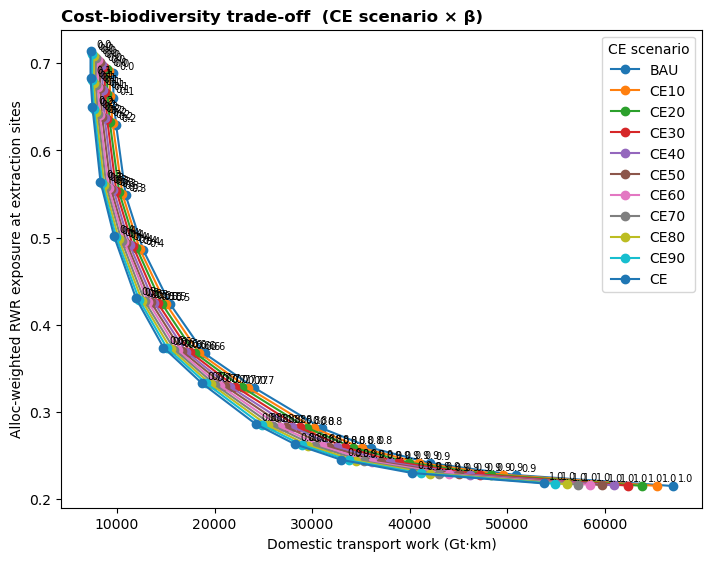

In [13]:
# Cost-biodiversity trade-off: one curve per CE scenario across beta (0 = BAU alloc -> 1 = CON alloc)
fig, ax = plt.subplots(figsize=(7, 5.5), constrained_layout=True)
for scen in SCENARIOS:
    s = sweep_df[sweep_df['scenario'] == scen].sort_values('beta')
    ax.plot(s['domestic_work_Gt_km'], s['rwr_exposure'], 'o-', label=scen)
    for _, row in s.iterrows():
        ax.annotate(f"{row['beta']:.1f}", (row['domestic_work_Gt_km'], row['rwr_exposure']),
                    textcoords='offset points', xytext=(4, 3), fontsize=7)
ax.set_xlabel('Domestic transport work (Gt·km)')
ax.set_ylabel('Alloc-weighted RWR exposure at extraction sites')
ax.set_title('Cost-biodiversity trade-off  (CE scenario × β)', loc='left', fontweight='bold')
ax.legend(title='CE scenario')
plt.show()